# $\chi^{(2)}$ e $\chi^{(3)}$: SHG, phase matching, $n_2$

### Subject: Nonlinear optics

In un dielettrico lineare $P=\varepsilon_0\chi E$. Se il campo è forte,

$$
P = \varepsilon_0\bigl(\chi^{(1)}E + \chi^{(2)}E^2 + \chi^{(3)}E^3 + \cdots\bigr).
$$

$\chi^{(2)}$ genera la **seconda armonica** (e DFG/OPA). $\chi^{(3)}$ rende
l'indice dipendente dall'intensità: $n=n_0+n_2 I$ (Kerr). Questo notebook è
un recap eseguibile; le slide del modulo restano in `data/`.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.4),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
print("Setup ready.")

Setup ready.


## 1. Second-harmonic generation e phase matching

Due fotoni a $\omega$ → un fotone a $2\omega$. L'ampiezza cresce solo se i
vettori d'onda combaciano: $\Delta k = k_{2\omega}-2k_\omega = 0$. Per uno
spessore $L$, in approssimazione di pompa indepleta,

$$
I_{2\omega}(L) \propto L^2\,\mathrm{sinc}^2\!\left(\frac{\Delta k L}{2}\right).
$$

La lunghezza di coerenza $L_c=\pi/|\Delta k|$ è quanto puoi allungare il
cristallo prima che l'armonica si disfi. Si sistema $\Delta k$ con birefringence
matching o con un reticolo di poling (QPM).

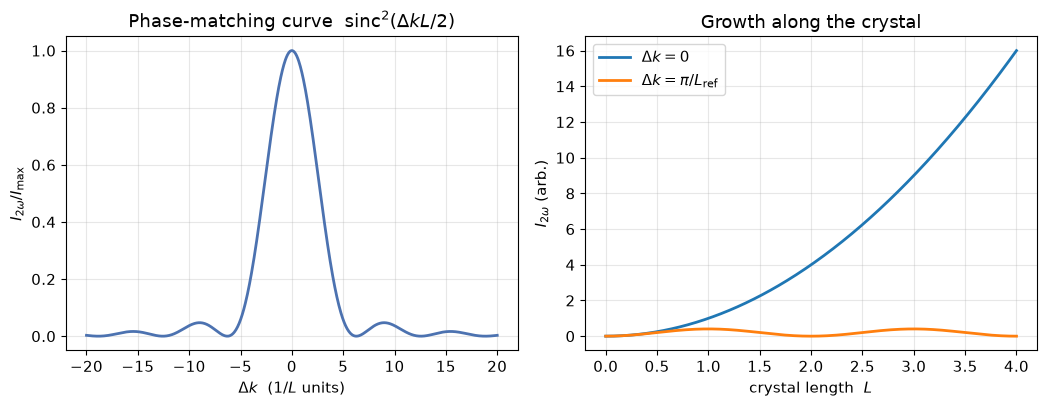

Δk=0: intensity grows as L².  Finite Δk: the harmonic breathes with period 2π/Δk.


In [2]:
def sinc2(x):
    y = np.sinc(x / np.pi)
    return y ** 2

L = 1.0
dk = np.linspace(-20, 20, 800)
I = sinc2(0.5 * dk * L)

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2))
axes[0].plot(dk, I, color="#4C72B0", lw=2)
axes[0].set_xlabel(r"$\Delta k$  ($1/L$ units)")
axes[0].set_ylabel(r"$I_{2\omega}/I_\mathrm{max}$")
axes[0].set_title(r"Phase-matching curve  $\mathrm{sinc}^2(\Delta k L/2)$")

z = np.linspace(0, 4, 400)
for dklab, lab in [(0.0, r"$\Delta k=0$"), (np.pi, r"$\Delta k=\pi/L_\mathrm{ref}$")]:
    axes[1].plot(z, z ** 2 * sinc2(0.5 * dklab * z), lw=2, label=lab)
axes[1].set_xlabel(r"crystal length  $L$")
axes[1].set_ylabel(r"$I_{2\omega}$ (arb.)")
axes[1].set_title("Growth along the crystal")
axes[1].legend()
plt.tight_layout()
plt.show()
print("Δk=0: intensity grows as L².  Finite Δk: the harmonic breathes with period 2π/Δk.")

## 2. Conservazione dell'energia: SHG, DFG, OPA

| Processo | Fotoni | Uso |
|---|---|---|
| SHG | $\omega+\omega\to 2\omega$ | raddoppiare un laser |
| DFG | $\omega_p-\omega_s\to\omega_i$ | infrarosso da due visibili |
| OPA | $\omega_p\to\omega_s+\omega_i$ | amplificare un seed debole |

Sono lo stesso vertice $\chi^{(2)}$ letto in direzioni diverse. Phase matching
resta $k_p=k_s+k_i$ (o $k_{2\omega}=2k_\omega$).

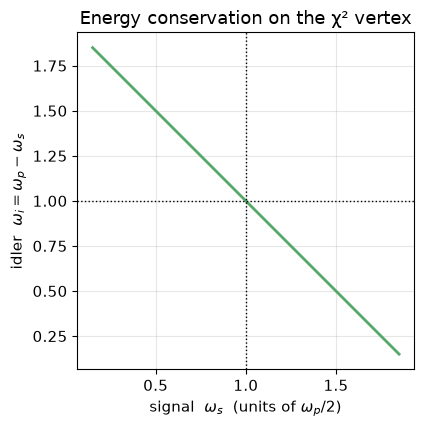

Degenerate OPA / SHG sits at ω_s = ω_i = ω_p/2.


In [3]:
wp = 2.0
ws = np.linspace(0.15, 1.85, 200)
wi = wp - ws
fig, ax = plt.subplots()
ax.plot(ws, wi, color="#55A868", lw=2)
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.axvline(1.0, color="k", ls=":", lw=1)
ax.set_xlabel(r"signal  $\omega_s$  (units of $\omega_p/2$)")
ax.set_ylabel(r"idler  $\omega_i=\omega_p-\omega_s$")
ax.set_title("Energy conservation on the χ² vertex")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()
print("Degenerate OPA / SHG sits at ω_s = ω_i = ω_p/2.")

## 3. $\chi^{(3)}$: indice di Kerr $n=n_0+n_2 I$

Uno sfasamento $\phi_\mathrm{NL}=n_2 I k_0 L$ (integrale $B$ se $I$ varia).
Conseguenze: **self-phase modulation** (spettro che si allarga), **self-focusing**
se $n_2>0$ e la potenza supera $P_\mathrm{cr}$, e — in una cavità — **Kerr-lens
mode-locking** (il Ti:zaffiro si comporta da otturatore saturo virtuale).

Qui un impulso gaussiano accumula chirp: il rosso avanza, il blu ritarda.

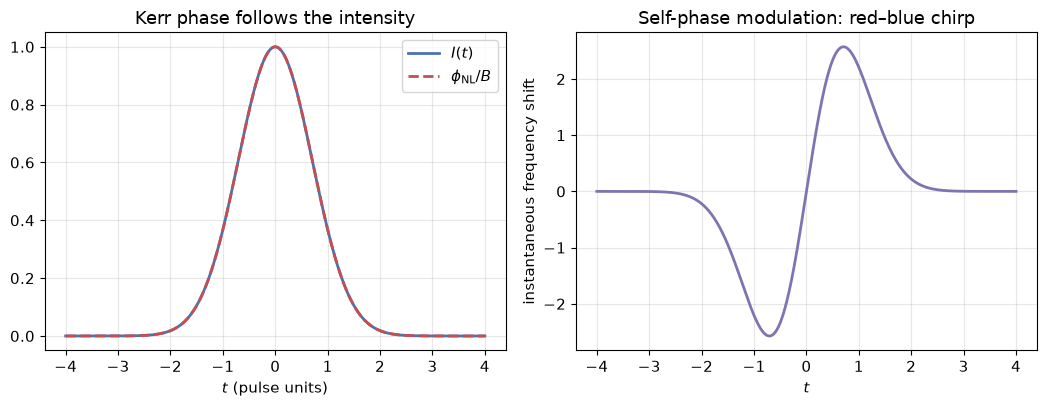

B-integral = 3.0 rad at pulse centre. Larger B → broader spectrum.


In [4]:
t = np.linspace(-4, 4, 2000)
I = np.exp(-t ** 2)
B = 3.0
phi = B * I
dphi = np.gradient(phi, t)

fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.2))
axes[0].plot(t, I, color="#4C72B0", lw=2, label=r"$I(t)$")
axes[0].plot(t, phi / B, color="#C44E52", lw=2, ls="--", label=r"$\phi_\mathrm{NL}/B$")
axes[0].set_xlabel(r"$t$ (pulse units)")
axes[0].set_title("Kerr phase follows the intensity")
axes[0].legend()
axes[1].plot(t, -dphi, color="#8172B2", lw=2)
axes[1].set_xlabel(r"$t$")
axes[1].set_ylabel(r"instantaneous frequency shift")
axes[1].set_title("Self-phase modulation: red–blue chirp")
plt.tight_layout()
plt.show()
print(f"B-integral = {B:.1f} rad at pulse centre. Larger B → broader spectrum.")

## Cosa ricordare

- $\chi^{(2)}$: SHG / DFG / OPA, tutti sullo stesso vertice a tre onde.
- Senza $\Delta k=0$ l'armonica non cresce: $\mathrm{sinc}^2(\Delta k L/2)$.
- $\chi^{(3)}$: $n_2$ → SPM, self-focusing, Kerr-lens mode-locking.

Prossimo passo naturale: four-wave mixing e conjugazione di fase, oppure il
collegamento col mode-locking in `04_quantum_electronics/04_cavity_qswitch_modelock.ipynb`.